# Day 7 lecture: Course review

<p class="lead">
One review of the whole course, organised by the five course learning outcomes (CLOs). For each outcome you get the key ideas in a table, one short worked example on the bundled data, and the mistakes that cost marks. A practice set at the end lets you test yourself before the final exam.
</p>

Open this notebook in JupyterLab from the course folder (next to the `data` folder) and run each cell from top to bottom with **Shift + Enter**.

---

## What you will be able to do

1. Match each course topic to the outcome it serves, and explain how descriptive, diagnostic, predictive and prescriptive analytics fit together (**CLO 1**).
2. Choose an honest chart and a correct KPI for a decision, and write a message title for it (**CLO 2**).
3. Find relationships in structured data (correlation) and unstructured data (sentiment scores), and state their limits (**CLO 3**).
4. Judge a forecast, a regression model and a simulation by the right measures: MAE and RMSE, R² on test data, and the probability of a loss (**CLO 4**).
5. Evaluate a business intelligence (BI) recommendation that weighs money against ethical and social effects, and write it for a manager (**CLO 5**).

> **How to use the questions in this notebook**
>
> **Predict, then reveal** boxes ask you to guess before running the next cell. Write your guess down first. **Check your understanding** boxes are short questions to answer in your own words, alone or with the person next to you. The **practice set** in Part 6 is in the style of the exam but uses different questions.

### The course on one page

| Day | Topics | Graded work | Main CLOs |
|---|---|---|---|
| Pre-class | Python and Jupyter basics, setup | Activity 1 | 1–4 |
| 1 | Data-driven decisions; kinds of analytics; exploring data in Python | Lab 1 (diamonds) | 1, 2, 3 |
| 2 | Visualisation principles; storytelling; dashboards and KPIs; Tableau | Lab 2, Assignment 1 (tips) | 1, 2, 3 |
| 3 | Text mining and sentiment; forecasting | Midterm, Lab 3, Lab 4 | 1, 2, 3, 5 |
| 4 | Predictive analytics; simple and multiple regression; model evaluation | Assignment 2 | 1–4 |
| 5 | Financial modelling; spreadsheet simulation in Excel | Lab 5 (MPG regression) | 4, 5 |
| 6 | BI strategy; BI case studies; ethics and societal context | Lab 6, Lab 7, Assignment 3 | 3, 4, 5 |
| 7 | Review; final exam; capstone launch | Final exam, Assignment 4 | 1–5 |

| Part | Outcome | Review topic |
|---|---|---|
| 1 | CLO 1 | Kinds of analytics; describing data; confounding |
| 2 | CLO 2 | Charts, KPIs and messages |
| 3 | CLO 3 | Data mining and text mining |
| 4 | CLO 4 | Forecasting, regression and simulation |
| 5 | CLO 5 | BI strategy, case evaluation and ethics |
| 6 | All | Practice set |
| 7 | | The final exam and this afternoon |

The setup cell loads the libraries and the four bundled data sources: diamonds, restaurant tips, car fuel economy (MPG) and the Mauna Loa CO₂ series that ships with `statsmodels`. It also points NLTK at the bundled VADER lexicon, so nothing is downloaded.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import statsmodels.api as sm
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from statsmodels.tsa.holtwinters import ExponentialSmoothing

warnings.filterwarnings("ignore", category=FutureWarning)

# NLTK reads the VADER lexicon straight from the bundled zip file
nltk.data.path.insert(0, str(Path("data/nltk_data").resolve()))

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
GREY = "#c9c7c1"   # context
INK = "#55534e"    # notes and labels
plt.rcParams.update({
    "figure.figsize": (9, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e1",
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})

diamonds = pd.read_csv("data/diamonds.csv")
tips = pd.read_csv("data/tips.csv")
mpg = pd.read_csv("data/mpg.csv")
co2 = sm.datasets.co2.load_pandas().data["co2"].resample("ME").mean().ffill()

for name, frame in [("diamonds", diamonds), ("tips", tips), ("mpg", mpg)]:
    print(f"{name:9} {frame.shape[0]:>6} rows x {frame.shape[1]} columns")
print(f"co2       {len(co2):>6} months, {co2.index[0]:%b %Y} to {co2.index[-1]:%b %Y}")

diamonds   53940 rows x 10 columns
tips         244 rows x 7 columns
mpg          398 rows x 9 columns
co2          526 months, Mar 1958 to Dec 2001


---

## Part 1 (CLO 1): Kinds of analytics, describing data, confounding

CLO 1 asks you to **describe the principles** of descriptive, predictive and prescriptive analytics and use them on a business problem. Every analysis in this course started from a decision.

| Kind | Question it answers | Course example | Typical output |
|---|---|---|---|
| **Descriptive** | What happened? | Revenue by day in the tips data | Tables, KPIs, charts, dashboards |
| **Diagnostic** | Why did it happen? | Why "Ideal" diamonds look cheap (Part 1 below) | Comparisons within groups, drill-down |
| **Predictive** | What is likely to happen? | Forecast of CO₂; MPG from car specifications | A forecast or prediction **with its error** |
| **Prescriptive** | What should we do? | Choose a supplier or a marketing strategy from a simulation | A recommended action and its trade-offs |

The four build on each other: you cannot recommend an action (prescriptive) without a sound prediction, and you cannot predict well without first describing and checking the data.

### The analytics workflow

1. **Frame** the decision and the question (who decides what, by when, using which measure).
2. **Get and check** the data: grain (what one row is), size, types, missing values, impossible values.
3. **Describe** it: centre, spread, shape, groups.
4. **Diagnose and model**: relationships, comparisons within groups, predictions.
5. **Validate**: test on unseen data, reconcile totals, look for confounders.
6. **Communicate and act**: one message, the evidence, the recommendation, its limits.

### Worked example: mean or median?

A distribution with a long right tail (a few very large values) pulls the **mean** above the **median**. Prices, incomes and bill sizes usually look like this.

In [2]:
print(diamonds["price"].describe().round(0).to_string())
print(f"\nMean minus median: {diamonds['price'].mean() - diamonds['price'].median():,.0f} US dollars")

count    53940.0
mean      3933.0
std       3989.0
min        326.0
25%        950.0
50%       2401.0
75%       5324.0
max      18823.0

Mean minus median: 1,532 US dollars


In the output above the mean is far above the median, so the "typical" diamond costs about the **median**. The middle half of the diamonds lies between the 25% and 75% values (the **interquartile range**).

### Worked example: a confounder

> **Predict, then reveal**
>
> Diamond cut runs from Fair (worst) to Ideal (best). Which cut do you expect to have the **highest** median price? Write your guess, then run the next cell.

In [3]:
CUTS = ["Fair", "Good", "Very Good", "Premium", "Ideal"]
by_cut = diamonds.groupby("cut")[["price", "carat"]].median().loc[CUTS]
by_cut.columns = ["median price ($)", "median carat"]
by_cut

,median price ($),median carat
cut,,
Fair,3282.0,1.00
Good,3050.5,0.82
Very Good,2648.0,0.71
Premium,3185.0,0.86
Ideal,1810.0,0.54


Ideal diamonds have the **lowest** median price in the table above, and also the smallest median carat (weight). Carat drives price far more than cut, and Ideal stones tend to be small. Carat is a **confounder**: it is related to both the group (cut) and the outcome (price).

The fair comparison holds carat roughly fixed: compare cuts **within** carat bands.

In [4]:
diamonds["carat band"] = pd.cut(diamonds["carat"], [0, 0.5, 1.0, 1.5, 2.0, 6.0],
                                labels=["up to 0.5", "0.5-1.0", "1.0-1.5", "1.5-2.0", "over 2.0"])
within = diamonds.pivot_table(values="price", index="carat band", columns="cut",
                              aggfunc="median", observed=True)[CUTS]
print("Median price (US dollars) by carat band and cut")
within.round(0)

Median price (US dollars) by carat band and cut


cut,Fair,Good,Very Good,Premium,Ideal
carat band,,,,,
up to 0.5,1002.0,685.0,684.0,827.0,825.0
0.5-1.0,2596.0,2817.0,2652.0,2579.0,2353.0
1.0-1.5,4544.0,5232.0,5839.0,5646.0,6460.0
1.5-2.0,8621.0,9791.0,11068.0,11034.0,11536.0
over 2.0,12617.0,14962.0,15680.0,15248.0,15990.0


Within the heavier bands in the output above, better cuts generally cost more, which is what a jeweller would expect. The overall table answered "what happened?" (descriptive). The within-band table starts to answer "why?" (diagnostic).

> **Check your understanding**
>
> 1. A manager asks: *"Which of our stores will run out of stock next week?"* Which kind of analytics is this, and what would the prescriptive follow-up question be?
> 2. Give the general rule from this example in one sentence, in words a manager would understand.

**Mistakes that cost marks (CLO 1):** calling a forecast "prescriptive"; reporting the mean of a skewed measure as "typical"; reading a missing value as 0; claiming a cause from a comparison that has a confounder.

---

## Part 2 (CLO 2): Charts, KPIs and messages

CLO 2 asks you to **design and use** visualisation and modelling tools to communicate for decisions.

| Task | Chart | Avoid |
|---|---|---|
| Compare a measure across categories | Bar chart, sorted, axis from zero | Pie with many slices, 3-D bars |
| Show change over time | Line chart | Bars for long series; uneven time gaps |
| Show a distribution | Histogram or box plot | A single average with no spread |
| Show a relationship between two measures | Scatter plot (hexbin for very many points) | Two lines on two different axes |
| Track a KPI against a target | KPI tile or bullet chart, with the target and period | A number with no comparison |

| Principle | Meaning |
|---|---|
| **Position beats area and angle** | Readers judge positions on a common scale most accurately |
| **Bars start at zero** | Bars are read by length; a cut axis exaggerates differences |
| **Highlight one thing** | Grey for context, one colour for the point you are making |
| **Message title** | The title states the finding ("Saturday brings the most revenue"), not the chart type |
| **Units and period** | Every axis and KPI says what it measures, in which unit, over which period |

### Worked example: a KPI computed the right way

The **tip rate** is tips ÷ bill. For a group of bills there are two ways to average it:

- **Ratio of sums:** total tips ÷ total bills. This is what the restaurant actually earned per dollar billed.
- **Mean of ratios:** average of each bill's tip rate. Every bill counts equally, so small bills with generous tips push it up.

In [5]:
DAYS = ["Thur", "Fri", "Sat", "Sun"]
per_bill_rate = 100 * tips["tip"] / tips["total_bill"]

kpi = tips.groupby("day").agg(bills=("tip", "size"), tips_total=("tip", "sum"),
                              bills_total=("total_bill", "sum")).loc[DAYS]
kpi["ratio of sums %"] = 100 * kpi["tips_total"] / kpi["bills_total"]
kpi["mean of ratios %"] = per_bill_rate.groupby(tips["day"]).mean().loc[DAYS]
kpi.round(2)

,bills,tips_total,bills_total,ratio of sums %,mean of ratios %
day,,,,,
Thur,62,171.83,1096.33,15.67,16.13
Fri,19,51.96,325.88,15.94,16.99
Sat,87,260.40,1778.40,14.64,15.32
Sun,76,247.39,1627.16,15.20,16.69


The two columns in the output above differ on every day. Neither is "wrong", but they answer different questions, so a dashboard must say which one it shows. For "how much of our revenue goes to tips?", use the **ratio of sums**. In Tableau, `SUM([Tip]) / SUM([Total Bill])` gives the ratio of sums at the level of the view.

The chart below follows the rules in the table: sorted bars, an axis from zero, one highlight colour, and a message title computed from the data rather than typed by hand.

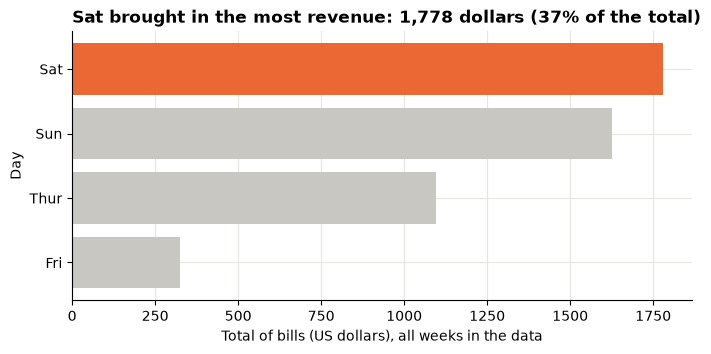

In [6]:
revenue = tips.groupby("day")["total_bill"].sum().loc[DAYS].sort_values()
top_day = revenue.idxmax()
colours = [ORANGE if day == top_day else GREY for day in revenue.index]

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(revenue.index, revenue.values, color=colours)
ax.set_title(f"{top_day} brought in the most revenue: {revenue.max():,.0f} dollars "
             f"({100 * revenue.max() / revenue.sum():.0f}% of the total)")
ax.set_xlabel("Total of bills (US dollars), all weeks in the data")
ax.set_ylabel("Day")
ax.set_xlim(0, None)
plt.show()

> **Check your understanding**
>
> 1. A colleague's chart compares two branches' sales with a vertical axis starting at 95,000. What two changes would you ask for?
> 2. A dashboard tile says "Conversion 4.2%". What is missing for a manager to act on it?

**Mistakes that cost marks (CLO 2):** a title that names the chart instead of the finding; no units or period; averaging percentages that have different denominators; a dashboard with many charts and no question.

---

## Part 3 (CLO 3): Data mining and text mining

CLO 3 asks you to **apply computational problem-solving** to find relationships in **structured** data (tables of numbers and categories) and **unstructured** data (free text).

| Method | Data | What it gives you | Watch out for |
|---|---|---|---|
| Group comparison, pivot table | Structured | Differences between groups | Confounders; small groups |
| Correlation *r* | Structured, two numeric measures | Direction and strength of a **straight-line** relationship, from −1 to +1 | Curves, outliers, causation |
| Tokenising, stopwords, word frequency | Unstructured | The topics people mention most | Domain words that every text contains |
| Lexicon sentiment (VADER) | Unstructured | A compound score from −1 (very negative) to +1 (very positive) | Sarcasm, domain words, mixed opinions |
| Text feature in a model | Both | A number (for example a sentiment score) used as a predictor | The score is only as good as the lexicon |

### Worked example: correlation in the car data

`mpg` is fuel economy in miles per US gallon, so **higher is better**. Six cars have no horsepower value; we leave them out of each pair rather than filling them with 0.

In [7]:
cols = ["mpg", "weight", "horsepower", "displacement", "acceleration", "model_year"]
print("Correlation of each measure with mpg")
print(mpg[cols].corr()["mpg"].drop("mpg").sort_values().round(2).to_string())

Correlation of each measure with mpg
weight         -0.83
displacement   -0.80
horsepower     -0.78
acceleration    0.42
model_year      0.58


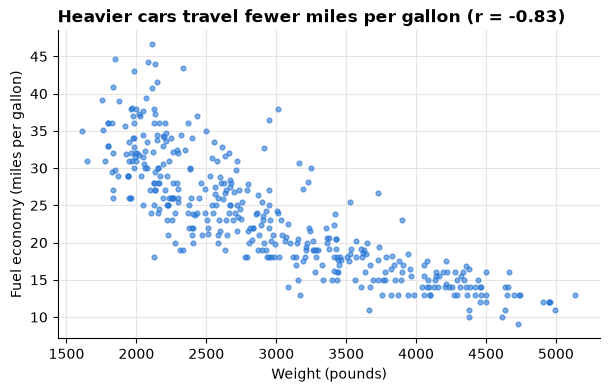

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(mpg["weight"], mpg["mpg"], s=12, alpha=0.6, color=BLUE)
r = mpg["weight"].corr(mpg["mpg"])
ax.set_title(f"Heavier cars travel fewer miles per gallon (r = {r:.2f})")
ax.set_xlabel("Weight (pounds)")
ax.set_ylabel("Fuel economy (miles per gallon)")
plt.show()

Weight, horsepower and displacement all correlate strongly and negatively with mpg in the output above, and they also correlate strongly **with each other** (heavy cars have big engines). That matters in Part 4: in a regression, predictors that move together share the credit, so their individual coefficients are less stable.

### Worked example: VADER sentiment rules

VADER looks up each word in a lexicon of rated words and then applies rules for **negation** ("not"), **intensifiers** ("very"), **"but"** (the second half counts more), capital letters and exclamation marks.

> **Predict, then reveal**
>
> Rank the five sentences below from most negative to most positive before you run the cell.

In [9]:
analyser = SentimentIntensityAnalyzer()
sentences = [
    "The delivery was good.",
    "The delivery was very good!",
    "The delivery was not good.",
    "The delivery was good, but the driver was rude.",
    "The delivery arrived on Tuesday.",
]
scores = pd.DataFrame({"sentence": sentences,
                       "compound": [analyser.polarity_scores(s)["compound"] for s in sentences]})
pd.set_option("display.max_colwidth", 60)
scores.sort_values("compound")

,sentence,compound
3,"The delivery was good, but the driver was rude.",-0.4678
2,The delivery was not good.,-0.3412
4,The delivery arrived on Tuesday.,0.0000
0,The delivery was good.,0.4404
1,The delivery was very good!,0.5400


In the output above, negation flips the score, the intensifier and "!" raise it, "but" lets the complaint dominate, and a neutral fact scores 0. VADER cannot read context: "the battery died" or "it's sick" may be scored wrongly, so always read a sample of texts next to their scores before you trust an average.

> **Check your understanding**
>
> 1. Two measures have *r* = 0.05. Can you conclude they are unrelated? What should you do first?
> 2. In Assignment 2 a sentiment score became a predictor of house price. Name one reason the score might mislead the model.

**Mistakes that cost marks (CLO 3):** "correlation proves cause"; keeping words like the product name, which appear in every review; reporting an average sentiment without reading any of the texts.

---

## Part 4 (CLO 4): Forecasting, regression and simulation

CLO 4 asks you to **develop predictive models** with three tools. All three answer "what is likely to happen?" and all three must be judged honestly.

| Tool | Use when | Judge it by | Course work |
|---|---|---|---|
| **Time-series forecasting** | One measure over time; the future follows the past pattern | Error on a **later** test period (MAE, RMSE, MAPE) against a baseline | Lab 4 (CO₂), Lab 7 (Excel forecast sheet) |
| **Linear regression** | An outcome explained by several measures | R², RMSE and MAE on **test** data; residuals | Lab 5 (MPG), Assignment 2 |
| **Spreadsheet simulation** | Inputs are uncertain; you need the range of outcomes, not one number | Distribution of the outcome: mean, percentiles, probability of a loss | Lab 6, Assignment 3 |

### 4a. Forecasting: test on the future, beat a baseline

We hide the last 24 months of CO₂, fit on the earlier months, and compare a **seasonal naive** baseline (same month last year) with **Holt-Winters** (level + trend + season).

In [10]:
def errors(actual, forecast):
    e = np.asarray(actual) - np.asarray(forecast)
    return {"MAE": np.mean(np.abs(e)), "RMSE": np.sqrt(np.mean(e ** 2)),
            "MAPE %": 100 * np.mean(np.abs(e / np.asarray(actual)))}


H = 24
train, test = co2.iloc[:-H], co2.iloc[-H:]
seasonal_naive = np.tile(train.iloc[-12:].values, H // 12)
hw = ExponentialSmoothing(train, trend="add", seasonal="add", seasonal_periods=12,
                          initialization_method="estimated").fit()
hw_forecast = hw.forecast(H)

print(f"Train: {train.index[0]:%b %Y} to {train.index[-1]:%b %Y} | test: {test.index[0]:%b %Y} to {test.index[-1]:%b %Y}")
pd.DataFrame({"seasonal naive": errors(test, seasonal_naive),
              "Holt-Winters": errors(test, hw_forecast)}).T.round(3)

Train: Mar 1958 to Dec 1999 | test: Jan 2000 to Dec 2001


,MAE,RMSE,MAPE %
seasonal naive,1.882,2.066,0.508
Holt-Winters,0.231,0.304,0.062


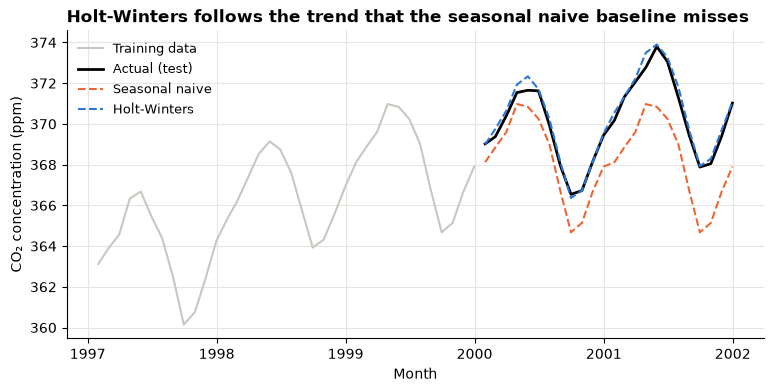

In [11]:
fig, ax = plt.subplots()
ax.plot(train["1997":].index, train["1997":], color=GREY, label="Training data")
ax.plot(test.index, test, color="black", linewidth=2, label="Actual (test)")
ax.plot(test.index, seasonal_naive, color=ORANGE, linestyle="--", label="Seasonal naive")
ax.plot(test.index, hw_forecast, color=BLUE, linestyle="--", label="Holt-Winters")
ax.set_title("Holt-Winters follows the trend that the seasonal naive baseline misses")
ax.set_xlabel("Month")
ax.set_ylabel("CO₂ concentration (ppm)")
ax.legend(frameon=False, loc="upper left", fontsize=9)
plt.show()

| Idea | Remember |
|---|---|
| **MAE** | Average size of the miss, in the data's units |
| **RMSE** | Like MAE but punishes big misses more; always at least as large as MAE |
| **MAPE** | Average miss as a % of the actual; misleading when actual values are near zero |
| **Baseline** | A model is only useful if it beats a simple baseline on the test period |
| **Never shuffle** | The test period must come after the training period |
| **Forecast interval** | The range widens with the horizon because uncertainty adds up |
| **Stationarity (ARIMA)** | ARIMA needs a stable mean; differencing removes a trend; ADF p ≤ 0.05 suggests stationary |

### 4b. Regression: interpret coefficients, judge on test data

We predict `mpg` from weight, horsepower and model year. Rows with no horsepower are dropped (6 cars). We hold back 20% of cars as a test set with a fixed `random_state`, so the split is the same each time.

In [12]:
cars = mpg.dropna(subset=["horsepower"])
features = ["weight", "horsepower", "model_year"]
X_train, X_test, y_train, y_test = train_test_split(
    cars[features], cars["mpg"], test_size=0.2, random_state=42)

model = LinearRegression().fit(X_train, y_train)
pred_train, pred_test = model.predict(X_train), model.predict(X_test)

print(f"Cars used: {len(cars)} | train: {len(X_train)} | test: {len(X_test)}")
print(f"Intercept: {model.intercept_:.2f}")
for name, coef in zip(features, model.coef_):
    print(f"Coefficient for {name:11}: {coef:+.4f}")
print(f"\nR² train: {r2_score(y_train, pred_train):.3f} | R² test: {r2_score(y_test, pred_test):.3f}")
print(f"Test MAE: {mean_absolute_error(y_test, pred_test):.2f} mpg | "
      f"test RMSE: {np.sqrt(mean_squared_error(y_test, pred_test)):.2f} mpg")

Cars used: 392 | train: 313 | test: 79
Intercept: -13.99
Coefficient for weight     : -0.0065
Coefficient for horsepower : -0.0088
Coefficient for model_year : +0.7594

R² train: 0.810 | R² test: 0.792
Test MAE: 2.51 mpg | test RMSE: 3.26 mpg


How to read the output above, in words a manager understands:

- **Coefficient of weight:** holding horsepower and model year fixed, each extra pound of weight goes with a change in mpg equal to the coefficient. That is tiny per pound, so say it per 1,000 pounds (multiply by 1,000).
- **Coefficient of model year:** cars one model year newer, at the same weight and horsepower, travel this many more miles per gallon on average.
- **R² on test data:** the share of the variation in mpg, among cars the model never saw, that the model explains. A test R² close to the training R² means the model **generalises**; a much lower test R² signals **overfitting**.
- **Test RMSE and MAE:** a typical prediction misses by about this many mpg.
- **Coefficients describe association in this data**, not what would happen if an engineer changed one feature.

A **residual plot** (actual minus predicted against predicted) should look like a shapeless cloud around zero. A curve means the straight-line model misses a pattern.

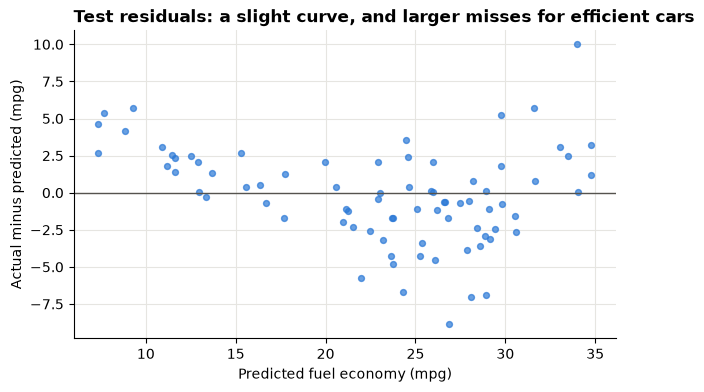

In [13]:
residuals = y_test - pred_test
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(pred_test, residuals, s=18, color=BLUE, alpha=0.7)
ax.axhline(0, color=INK, linewidth=1)
ax.set_title("Test residuals: a slight curve, and larger misses for efficient cars")
ax.set_xlabel("Predicted fuel economy (mpg)")
ax.set_ylabel("Actual minus predicted (mpg)")
plt.show()

The plot above is not a perfect cloud: the misses are larger for the most fuel-efficient cars, and the middle of the range is slightly over-predicted. A straight line is a good first model here, not a perfect one. Say so in a report, together with the test error.

### 4c. Simulation: the range of outcomes, not one number

Excel simulation on Days 5–6 used random inputs to see how uncertain inputs produce uncertain profit. The same idea in Python makes the steps explicit. A **synthetic** example: a pop-up shop sells a product for 40 currency units. Monthly demand is uncertain (normal, mean 3,000, standard deviation 600 units). The unit cost is somewhere between 22 and 28 (uniform). Fixed costs are 30,000 a month.

| Excel | Python here | Meaning |
|---|---|---|
| `=RAND()` | `rng.uniform(0, 1)` | A random number between 0 and 1 |
| `=NORM.INV(RAND(), mean, sd)` | `rng.normal(mean, sd)` | A random draw from a normal distribution |
| `=RANDBETWEEN(a, b)` | `rng.integers(a, b + 1)` | A random whole number from a to b |
| Fill down 10,000 rows | `size=10_000` | Many trials |
| Paste values / a fixed seed | `np.random.default_rng(7)` | Freeze the random numbers so results can be checked |
| Data Table (what-if) | A loop over input values | Outcome for each scenario |

In [14]:
rng = np.random.default_rng(7)
TRIALS = 10_000
demand = np.clip(rng.normal(3000, 600, TRIALS), 0, None).round()
unit_cost = rng.uniform(22, 28, TRIALS)
profit = demand * (40 - unit_cost) - 30_000

summary = pd.Series({
    "mean profit": profit.mean(),
    "5th percentile": np.percentile(profit, 5),
    "median": np.median(profit),
    "95th percentile": np.percentile(profit, 95),
    "probability of a loss (%)": 100 * (profit < 0).mean(),
})
print(summary.round(1).to_string())

mean profit                  14814.0
5th percentile               -1287.4
median                       14353.9
95th percentile              32520.4
probability of a loss (%)        6.6


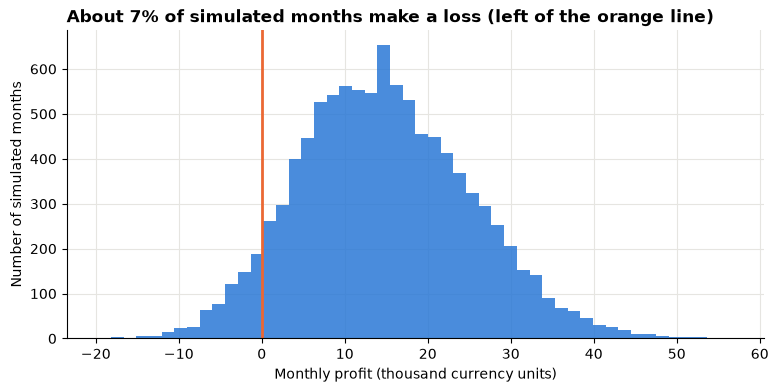

In [15]:
fig, ax = plt.subplots()
ax.hist(profit / 1000, bins=50, color=BLUE, alpha=0.85)
ax.axvline(0, color=ORANGE, linewidth=2)
ax.set_title(f"About {100 * (profit < 0).mean():.0f}% of simulated months make a loss (left of the orange line)")
ax.set_xlabel("Monthly profit (thousand currency units)")
ax.set_ylabel("Number of simulated months")
plt.show()

The mean in the output above looks healthy, but the risk is in the left tail. A manager should hear both: "we expect about the mean, but there is roughly this percentage chance of a loss, and in a bad month (5th percentile) we lose about this much". That sentence is the bridge from **predictive** to **prescriptive**.

> **Check your understanding**
>
> 1. Why must the CO₂ test period come after the training period, but the car test set can be a random 20%?
> 2. The simulation's mean profit doubles if fixed costs fall. Does the probability of a loss necessarily fall to zero? Why not?

**Mistakes that cost marks (CLO 4):** judging a model on its training data; quoting R² with no error in units; "each extra pound **causes**…"; reporting only the mean of a simulation; forgetting to freeze random numbers before charting them.

---

## Part 5 (CLO 5): BI strategy, case evaluation and ethics

CLO 5 asks you to **evaluate** the impact of BI tools within a case and write a **managerial report** that considers **ethical and societal** contexts.

| Element of a BI strategy | Questions to ask |
|---|---|
| **Business goals** | Which decisions will the BI tools improve, and how will we measure the improvement? |
| **People** | Who uses the dashboards? What skills and training do they need? Who owns each KPI? |
| **Process** | How do insights reach decisions (meetings, alerts, approvals)? |
| **Data and governance** | Single source of truth, definitions, data quality checks, access rights, privacy |
| **Technology** | Which tools (Python, Excel, Tableau) for which job, and how they connect |
| **Value and adoption** | Is the dashboard used? Did the decision or the KPI improve? |

| Ethical and societal issue | Example from the course | Mitigation |
|---|---|---|
| **Privacy and consent** | Reviews, customer or employee records | Collect the minimum, anonymise, state the purpose |
| **Bias and fairness** | A model trained on past decisions repeats their bias | Check results by group; involve the people affected |
| **Transparency** | A score nobody can explain | Document the method and its limits |
| **Supply chain and environment** | Cheaper supplier with labour or emission violations | Price the risk; include brand, regulation and social cost |
| **Honest communication** | Cut axes, selective time windows | Show the full picture and the uncertainty |

### Worked example: pricing an ethical choice

A **synthetic** case. A product sells 20,000 units a year. A standard supplier leaves a margin of 50 currency units per unit; a certified supplier with fair labour and lower emissions leaves 44. Fixed costs are 600,000 a year. How large is the profit gap, and how much extra demand would the certified option need to break even with the standard one?

In [16]:
units, fixed = 20_000, 600_000
margin_standard, margin_certified = 50, 44

profit_standard = units * margin_standard - fixed
profit_certified = units * margin_certified - fixed
gap = profit_standard - profit_certified
# Demand at which the certified option earns the same profit as the standard option
break_even_units = (profit_standard + fixed) / margin_certified

print(f"Profit, standard supplier:  {profit_standard:>10,.0f}")
print(f"Profit, certified supplier: {profit_certified:>10,.0f}")
print(f"Gap: {gap:,.0f} ({100 * gap / profit_standard:.1f}% of the standard profit)")
print(f"Certified option breaks even with standard at {break_even_units:,.0f} units "
      f"(+{100 * (break_even_units / units - 1):.1f}% demand)")

Profit, standard supplier:     400,000
Profit, certified supplier:    280,000
Gap: 120,000 (30.0% of the standard profit)
Certified option breaks even with standard at 22,727 units (+13.6% demand)


A small cut in the **margin** becomes a large cut in **profit** when fixed costs are high (operating leverage). The break-even line turns an ethical debate into a testable question for the board: *"Is it plausible that the certified option wins this much extra demand, or protects us from losses of this size (fines, boycotts, lost contracts)?"* The answer still needs judgement, but now it is an informed judgement.

### A managerial report in five moves

1. **Bottom line first:** the recommendation in one sentence.
2. **Evidence:** two or three numbers that support it, with units and the period.
3. **Trade-offs:** what is given up (money, risk, ethics, time) and why it is worth it.
4. **Limits:** what the data cannot show; key assumptions.
5. **Next steps:** what to monitor, and the KPI that will show whether the decision worked.

> **Check your understanding**
>
> 1. A company has many dashboards but decisions have not changed. Which element of a BI strategy would you examine first, and why?
> 2. Name one stakeholder outside the company who is affected by the supplier choice above, and how.

**Mistakes that cost marks (CLO 5):** a recommendation with no numbers; ethics mentioned in one sentence at the end instead of weighed against the money; no limits or next steps; "the data proves" instead of "the data suggests".

---

## Part 6: Practice set

Answer on paper first, then check with the person next to you. These questions are **practice**: they are in the style of the exam, but the exam questions are different. Answers are discussed at the end of the review.

**P1 (CLO 1).** Label each question as descriptive, diagnostic, predictive or prescriptive: (a) *How many tablets did we return last quarter?* (b) *How many staff should we roster each evening next week to keep waiting times under 10 minutes?* (c) *Why did returns rise in March?* (d) *How many tablets will we sell in December?*

**P2 (CLO 1).** From the confounding example in Part 1, explain to a jewellery buyer, in two sentences, why the table "median price by cut" alone would lead to a wrong conclusion.

**P3 (CLO 2).** Choose a chart for each task and name one design rule for it: (a) monthly revenue for the last three years; (b) the spread of delivery times for four couriers; (c) the relationship between advertising spend and sales for 200 stores.

**P4 (CLO 2).** A shop had 30 sales from 600 visits on Monday and 90 sales from 1,200 visits on Saturday. Compute the overall conversion rate correctly, and the (incorrect) average of the two daily rates.

**P5 (CLO 3).** VADER scores *"The app is not bad at all"* as positive. Explain why, and give one example of a review VADER would probably score wrongly.

**P6 (CLO 3).** Using the correlation output in Part 3, which single measure has the strongest relationship with mpg? Does this mean reducing a car's weight will raise its mpg by a predictable amount? Explain.

**P7 (CLO 4).** A shop forecast weekly sales of 100, 120, 110 and 90 units; actual sales were 110, 115, 100 and 95. Compute the MAE and the RMSE (show the errors). Which is larger, and why must it be?

**P8 (CLO 4).** Using the regression output in Part 4, (a) state the effect of 1,000 extra pounds of weight on predicted mpg, holding the other two measures fixed; (b) compare the training and test R² and say what the comparison tells you.

**P9 (CLO 4).** Using the simulation output in Part 4, write one sentence for a manager that gives the expected monthly profit and the risk of a loss. Then say why a fixed seed (or **Paste Values** in Excel) matters before you chart the results.

**P10 (CLO 4).** Why does a forecast interval get wider for months further in the future?

**P11 (CLO 5).** A hospital wants to use a BI dashboard that flags nurses whose overtime is "too high". Name two ethical risks and one safeguard for each.

**P12 (CLO 5).** Using the worked example in Part 5, write the bottom-line sentence of a recommendation **for** the certified supplier, with two numbers from the output.

---

## Part 7: The final exam and this afternoon

> **The final exam (20% of the course grade, CLO 1–5)**
>
> - **When:** today, periods 3–4, straight after this review.
> - **Length:** 90 minutes, 100 marks, all five learning outcomes, including forecasting, regression, simulation, and BI and ethics.
> - **Format:** multiple-choice questions, short written answers, and a data-interpretation section in which you read **printed** Python output; no computer is needed.
> - **Closed book.** Bring a pen and a **basic calculator**. No notes, laptops, phones or internet.
> - **How to score well:** quote the numbers you use, with units; say "is associated with", not "causes"; judge models on test data; give recommendations with their trade-offs.

**This afternoon (lab, 13:45–17:20):** the launch of [Assignment 4, the capstone](D7_assignment4_capstone.md) (25%, due **Sunday 29 November, 23:59 China Standard Time**), followed by a studio session with feedback checkpoints. Support for Assignments 2 and 3 (due Sunday 22 November) is available in the same session. All deadlines are on the [schedule](schedule.md).